<a href="https://colab.research.google.com/github/Alt4660/con5200-card-replication/blob/main/notebooks/02_robustness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Section 3: Robustness, Where You Go Beyond (28 pts)

ECON 5200 Midterm Project · Replication Study

**AI is allowed in this notebook**, as a documented co-pilot under P.R.I.M.E. File every exchange, in full, in [`ai-appendix.md`](../ai-appendix.md) under the exercise it belongs to. If you cannot explain a line, you cannot submit it.

At least four exercises the original did not run. Choose from modern estimators, a specification curve, sensitivity to unobserved confounding, inference (clustering at the level of treatment assignment, a wild cluster bootstrap if clusters are few), bandwidth or instrument strength, and placebo tests, or justify an alternative. For each one: what you did, what you found, and what it implies about the original claim.

## Setup

In [5]:
import sys, os, subprocess
if "google.colab" in sys.modules and not os.path.exists("download_data.py"):
    subprocess.run(["git", "clone", "https://github.com/Alt4660/con5200-card-replication"], check=True)
    os.chdir("con5200-card-replication")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "linearmodels"], check=True)

In [6]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from linearmodels.iv import IV2SLS

# The repository root, whether this runs from notebooks/ (Jupyter) or from the root (reproduce.py).
ROOT = Path.cwd() if (Path.cwd() / "download_data.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
(ROOT / "output").mkdir(exist_ok=True)

from download_data import MY_PAPER, PAPERS, fetch

## Data

In [7]:
# Set MY_PAPER once, in download_data.py. fetch() downloads into data/ only if a file is missing.
if MY_PAPER:
    paths = fetch(MY_PAPER)
    print(PAPERS[MY_PAPER]["paper"])
    raw = pd.read_stata(paths[0])
    print(raw.shape)
else:
    print("TODO: set MY_PAPER in download_data.py (castle, card, lee, dw, hansen or abortion).")

  data/card.dta  0.5 MB
Card (1995), proximity to college and returns to schooling
(3010, 37)


In [8]:
from linearmodels.iv import IV2SLS

REGIONS = " + ".join(f"reg66{i}" for i in range(2, 10))

def build(raw, cuts=None, labels=None):
    df = raw.copy()
    df["agesq"] = df["age"] ** 2
    for col in ["fatheduc", "motheduc"]:
        df[f"{col}_miss"] = df[col].isna().astype(int)
        df[col] = df[col].fillna(df[col].mean())
    family = "fatheduc + motheduc + fatheduc_miss + motheduc_miss + momdad14 + sinmom14"
    if cuts is not None:
        mom = pd.cut(df["motheduc"], cuts, labels=labels).astype(str)
        dad = pd.cut(df["fatheduc"], cuts, labels=labels).astype(str)
        dummies = pd.get_dummies(mom + "_" + dad, prefix="pe", drop_first=True).astype(int)
        df = pd.concat([df, dummies], axis=1)
        family += " + " + " + ".join(dummies.columns)
    return df, f"black + south + smsa + smsa66 + {REGIONS} + {family}"


df, CONTROLS = build(raw, [-1, 11, 12, 30], ["lt12", "hs", "morehs"])

SIMPLE = f"lwage ~ 1 + exper + expersq + {CONTROLS} + [educ ~ nearc4]"

## The four exercises

### Exercise 1: Inference that does not need a strong first stage

What I did: I used the simple version of the IV, with nearc4 as the only instrument and experience treated as exogenous. First I got the usual confidence interval, with default and with robust standard errors. Then I built an Anderson-Rubin set. For each guess of the return, I took that guess times years of schooling away from log wage and asked whether nearc4 still predicts what is left. A guess stays in the set if it doesn't. I did this over a grid of guesses from -0.10 to 0.60 and kept the ones that weren't rejected at the 5% level. This doesn't depend on the first stage being strong, which is the point of doing it.

In [9]:
# Exercise 1: does the answer survive inference that does not rely on a strong first stage?
rows = []
for label, cov in [("2SLS, default standard errors", "unadjusted"), ("2SLS, robust standard errors", "robust")]:
    r = IV2SLS.from_formula(SIMPLE, data=df).fit(cov_type=cov)
    lo, hi = r.conf_int().loc["educ"]
    rows.append([label, r.params["educ"], r.std_errors["educ"], lo, hi])


def ar_pvalue(b0):
    d = df.assign(y0=df["lwage"] - b0 * df["educ"])
    m = smf.ols(f"y0 ~ nearc4 + exper + expersq + {CONTROLS}", data=d).fit(cov_type="HC1")
    return m.pvalues["nearc4"]

grid = np.round(np.arange(-0.10, 0.60, 0.002), 3)
kept = [b for b in grid if ar_pvalue(b) > 0.05]
rows.append(["Anderson-Rubin 95% set", r.params["educ"], np.nan, min(kept), max(kept)])

ex1 = pd.DataFrame(rows, columns=["method", "estimate", "se", "ci_low", "ci_high"])
ex1.to_csv(ROOT / "output" / "ex1_weak_iv_inference.csv", index=False)
print("number of grid points kept:", len(kept), "of a possible", int(round((max(kept) - min(kept)) / 0.002)) + 1)
ex1.round(3)

number of grid points kept: 119 of a possible 119


,method,estimate,se,ci_low,ci_high
0,"2SLS, default standard errors",0.14,0.053,0.036,0.244
1,"2SLS, robust standard errors",0.14,0.053,0.037,0.243
2,Anderson-Rubin 95% set,0.14,NaN,0.044,0.280


What I found: Using nearc4 as the only instrument, the IV return is 0.140. The usual 95% confidence interval is about 0.036 to 0.244, and the robust interval is almost the same. The Anderson-Rubin interval is slightly wider, going from about 0.044 to 0.280, but it still stays above zero.

What it implies about the original claim: The first-stage F-statistic is 16.19, so the instrument seems strong enough that weak-instrument concerns do not change the main result. Card's finding of a positive return to education is supported. However, this does not prove that the IV estimate is higher than OLS. My OLS estimate of 0.072 falls inside all three intervals, so I cannot say that the true return is higher than OLS. This also fits with Card's point that his IV estimates are not very precise.

### Exercise 2: Specification curve over the choices the paper leaves open

What I did: The paper leaves three choices somewhat open, so I decided to test all the possible combinations. First, I tried five different ways of grouping parents' education into classes, including leaving it out entirely. Second, I tested both treating experience as endogenous, as in the paper's main specification, and treating it as exogenous. Finally, I used both default and robust standard errors. Combining these choices gives 20 different specifications. I ran the IV for each one and recorded the estimated return and its standard error. I then sorted the 20 estimates and plotted them with their 95% confidence intervals, using the paper's IV estimate (0.132) and OLS estimate (0.073) as reference lines.

smallest and largest IV across 20 specifications: 0.1281 0.1423


,parent_classes,experience,std_errors,iv_return,se
0,no interaction dummies,endogenous,unadjusted,0.1281,0.0484
1,no interaction dummies,endogenous,robust,0.1281,0.0479
2,no interaction dummies,exogenous,unadjusted,0.1347,0.0535
3,no interaction dummies,exogenous,robust,0.1347,0.0529
4,<12 / 12 / >12,endogenous,unadjusted,0.1314,0.0469
5,<12 / 12 / >12,endogenous,robust,0.1314,0.0463
6,<12 / 12 / >12,exogenous,unadjusted,0.1400,0.0531
7,<12 / 12 / >12,exogenous,robust,0.1400,0.0525
8,<12 / 12-15 / 16+,endogenous,unadjusted,0.1335,0.0500
9,<12 / 12-15 / 16+,endogenous,robust,0.1335,0.0494


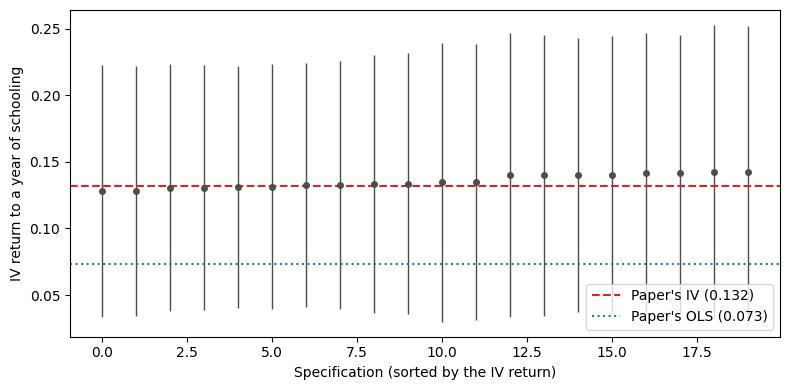

In [10]:
# Exercise 2: The paper does not explain how it grouped parent education, whether experience is endogenous, or which standard errors it used.
# I test all the different combinations to see how much the IV return changes.
schemes = {
    "no interaction dummies": (None, None),
    "<12 / 12 / >12": ([-1, 11, 12, 30], ["a", "b", "c"]),
    "<12 / 12-15 / 16+": ([-1, 11, 15, 30], ["a", "b", "c"]),
    "<12 / 12 / 13-15 / 16+": ([-1, 11, 12, 15, 30], ["a", "b", "c", "d"]),
    "<10 / 10-11 / 12 / >12": ([-1, 9, 11, 12, 30], ["a", "b", "c", "d"]),
}
rows = []
for name, (cuts, labs) in schemes.items():
    d, C = build(raw, cuts, labs)
    for exper_endog in [True, False]:
        if exper_endog:
            f = f"lwage ~ 1 + {C} + [educ + exper + expersq ~ nearc4 + age + agesq]"
        else:
            f = f"lwage ~ 1 + exper + expersq + {C} + [educ ~ nearc4]"
        for cov in ["unadjusted", "robust"]:
            r = IV2SLS.from_formula(f, data=d).fit(cov_type=cov)
            rows.append([name, "endogenous" if exper_endog else "exogenous", cov,
                         r.params["educ"], r.std_errors["educ"]])

curve = pd.DataFrame(rows, columns=["parent_classes", "experience", "std_errors", "iv_return", "se"])
curve.to_csv(ROOT / "output" / "ex2_spec_curve.csv", index=False)

order = curve.sort_values("iv_return").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(order.index, order["iv_return"], yerr=1.96 * order["se"], fmt="o", ms=4, lw=1, color="0.3")
ax.axhline(0.132, color="C3", ls="--", label="Paper's IV (0.132)")
ax.axhline(0.073, color="C0", ls=":", label="Paper's OLS (0.073)")
ax.set_xlabel("Specification (sorted by the IV return)")
ax.set_ylabel("IV return to a year of schooling")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(ROOT / "output" / "ex2_spec_curve.png", dpi=200)
print("smallest and largest IV across", len(curve), "specifications:",
      round(curve["iv_return"].min(), 4), round(curve["iv_return"].max(), 4))
curve.round(4)

What I found: I ran 20 different versions of the IV, using five different ways of grouping parents into education classes, treating experience as either endogenous or exogenous, and using either default or robust standard errors. The IV return stays within a fairly narrow range, from 0.128 to 0.142, with the paper's estimate of 0.132 falling right in the middle. Most of the difference seems to come from treating experience as exogenous, which raises the estimate by around 0.01. The different class cutoffs have a smaller effect of about 0.005, while using robust standard errors only changes the standard error by around 1%.

What this implies about the original claim: Overall, the choices that the paper does not fully explain seem to have a fairly limited effect on the results. The full range of estimates is only 0.014, compared with a standard error of about 0.05, and all of the versions remain well above the OLS return of roughly 0.07. So, the main finding seems to hold across the different choices I tested, and the small difference between my estimate and the paper's 0.132 is likely just due to those modeling choices rather than anything more substantial.



### Exercise 3: Balance check on the instrument

What I did: The idea is that if living near a college is basically random after controlling for region and whether someone lived in a city or rural area, it should not predict characteristics that were already determined before his schooling decisions. To check this, I looked at seven characteristics: KWW score, IQ, father's education, mother's education, whether he lived with both parents at age 14, whether he lived with a single mother at 14, and race. For each one, I ran a regression on nearc4, including the 1966 region and city controls, and recorded the nearc4 coefficient and its t-statistic. I used robust standard errors throughout, and each regression only includes men with non-missing observations for the particular characteristic being tested.

In [11]:
# Exercise 3: balance check. If nearc4 is as good as random once I account for region and
# urban/rural in 1966, it should not predict who the men are before schooling decisions.
# I regress each pre-determined characteristic on nearc4 (plus those same controls).
rows = []
for var in ["KWW", "IQ", "fatheduc", "motheduc", "momdad14", "sinmom14", "black"]:
    d = raw.dropna(subset=[var])
    m = smf.ols(f"{var} ~ nearc4 + smsa66 + {REGIONS}", data=d).fit(cov_type="HC1")
    rows.append([var, int(m.nobs), d[var].mean(), m.params["nearc4"], m.bse["nearc4"], m.tvalues["nearc4"]])

ex3 = pd.DataFrame(rows, columns=["characteristic", "n", "mean", "nearc4_coef", "se", "t_stat"])
ex3.to_csv(ROOT / "output" / "ex3_balance.csv", index=False)
ex3.round(3)

,characteristic,n,mean,nearc4_coef,se,t_stat
0,KWW,2963,33.541000,0.676,0.374,1.809
1,IQ,2061,102.449997,0.348,0.808,0.431
2,fatheduc,2320,10.003000,0.259,0.184,1.405
3,motheduc,2657,10.348000,-0.102,0.147,-0.695
4,momdad14,3010,0.789000,-0.034,0.018,-1.839
5,sinmom14,3010,0.101000,0.021,0.013,1.574
6,black,3010,0.234000,0.048,0.017,2.766


What I found: I checked whether living near a college is related to characteristics men already had before making their schooling decisions, controlling for region and urban or rural location in 1966. The differences in parents' education and IQ are generally small and not statistically significant. There are two results that are somewhat closer to significance: men living near a college score about 0.7 points higher on the KWW test (t = 1.8), and are slightly less likely to have lived with both parents at age 14 (t = -1.8). The clearest difference is race. Men living near a college are about 4.8 percentage points more likely to be Black (t = 2.77), and this result still passes a rough Bonferroni adjustment for the seven tests I ran.

What this implies about the original claim: So, the instrument seems mostly balanced across the characteristics I tested, although there are still some differences worth considering. The racial difference is already controlled for in Card's specification, so it does not directly bias the main result. However, it does suggest that living near a college is not completely random, even after controlling for region. There is also only so much I can check using the survey data, since other differences that were not measured could still matter. For example, family attitudes toward education, which Card raises as a concern, could still be related to where someone grows up. Overall, this adds some support to the family-background concern from Section 1 and suggests that the exclusion assumption should be treated with some caution.

### Exercise 4: How big a direct effect would undo the IV result

What I did: The IV assumes that living near a college affects wages only through its effect on schooling. To see how sensitive the results are to this assumption, I looked at what happens if living near a college also has some direct effect on log wages, which I call delta. Based on the maths, the adjusted IV return should equal my original IV estimate minus delta divided by the first stage. I checked that this formula works by manually subtracting a direct effect of 0.02 from log wages and running the IV again, and both approaches gave the same result. After that, I tested a range of delta values from -0.02 to 0.05 and plotted the resulting IV estimates with their 95% confidence intervals. I also worked out which values of delta would bring the IV estimate down to the OLS level and which would make the confidence interval reach zero.

delta=0.02: re-estimated 0.0801 | formula 0.0801
simple IV 0.14 | first stage 0.3336 | OLS 0.0721
a direct effect of 0.0227 makes IV equal OLS
a direct effect of 0.0124 makes the 95% interval reach zero


,delta,iv_return,ci_low,ci_high
0,-0.020,0.200,0.097,0.303
1,-0.015,0.185,0.082,0.288
2,-0.010,0.170,0.067,0.273
3,-0.005,0.155,0.052,0.258
4,0.000,0.140,0.037,0.243
5,0.005,0.125,0.022,0.228
6,0.010,0.110,0.007,0.213
7,0.015,0.095,-0.008,0.198
8,0.020,0.080,-0.023,0.183
9,0.025,0.065,-0.038,0.168


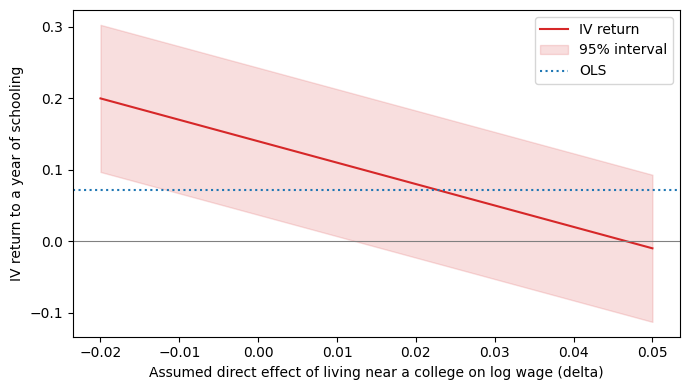

In [12]:
# Exercise 4: how big a direct effect of living near a college on wages (one that does NOT go
# through schooling) would it take to undo the IV result?
# If proximity had a direct effect delta on log wage, the true IV return would be
#     b(delta) = b - delta / pi
# where b is my IV estimate and pi is the first stage (how much nearc4 moves schooling).
iv_r = IV2SLS.from_formula(SIMPLE, data=df).fit(cov_type="robust")
b, se = iv_r.params["educ"], iv_r.std_errors["educ"]
pi = smf.ols(f"educ ~ nearc4 + exper + expersq + {CONTROLS}", data=df).fit().params["nearc4"]
ols_b = smf.ols(f"lwage ~ educ + exper + expersq + {CONTROLS}", data=df).fit().params["educ"]

# Check of the formula: re-estimate with delta = 0.02 taken out of log wage by hand.
d2 = df.assign(y2=df["lwage"] - 0.02 * df["nearc4"])
check = IV2SLS.from_formula(f"y2 ~ 1 + exper + expersq + {CONTROLS} + [educ ~ nearc4]", data=d2).fit(cov_type="robust")
print("delta=0.02: re-estimated", round(check.params["educ"], 4), "| formula", round(b - 0.02 / pi, 4))

deltas = np.round(np.arange(-0.02, 0.0501, 0.005), 3)
ex4 = pd.DataFrame({"delta": deltas, "iv_return": b - deltas / pi})
ex4["ci_low"] = ex4["iv_return"] - 1.96 * se
ex4["ci_high"] = ex4["iv_return"] + 1.96 * se
ex4.to_csv(ROOT / "output" / "ex4_exclusion_sensitivity.csv", index=False)

delta_ols = pi * (b - ols_b)            # delta at which IV falls to the OLS number
delta_zero = pi * (b - 1.96 * se)       # delta at which the 95% interval reaches zero
print("simple IV", round(b, 4), "| first stage", round(pi, 4), "| OLS", round(ols_b, 4))
print("a direct effect of", round(delta_ols, 4), "makes IV equal OLS")
print("a direct effect of", round(delta_zero, 4), "makes the 95% interval reach zero")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ex4["delta"], ex4["iv_return"], color="C3", label="IV return")
ax.fill_between(ex4["delta"], ex4["ci_low"], ex4["ci_high"], color="C3", alpha=0.15, label="95% interval")
ax.axhline(ols_b, color="C0", ls=":", label="OLS")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("Assumed direct effect of living near a college on log wage (delta)")
ax.set_ylabel("IV return to a year of schooling")
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "output" / "ex4_exclusion_sensitivity.png", dpi=200)
ex4.round(3)

What I found: I looked at how much a direct effect of living near a college on wages would have to matter to change the IV results. If living near a college affects wages directly by some amount delta, the true IV return would be my estimate minus delta divided by the first stage. A direct effect of around 0.012, or roughly 1.2% higher wages, would be enough for the 95% confidence interval to include zero. If the direct effect is closer to 0.023, the IV return falls to about the same level as the OLS estimate. This is roughly half of the overall wage difference between men who live near and far from a college (0.047).

What this implies about the original claim: So, the positive return to schooling seems reasonably robust, but the claim that the IV estimate is higher than OLS depends more heavily on the exclusion assumption. Card's own test of a possible direct effect estimated it at 0.015, with a standard error of 0.029, which is not precise enough to rule out effects large enough to change the conclusion. Basically, if around half of the wage advantage for men living near a college comes from something other than schooling, the IV estimate would be no higher than OLS. The paper's evidence does not really rule out this possibility, so the main finding still holds, but it depends on an assumption that is difficult to test directly.